In [6]:
# SPY Next-Day Return Prediction Using Multiple Linear Regression

# **Course:** CSIS 3360 – Fundamentals of Data Analytics  
# **Team Member:** Chấn Nguyên  
# **Algorithm:** Multiple Linear Regression  

## Objective

# The purpose of this analysis is to determine whether historical SPY market conditions can be used to predict the percentage return of SPY on the next trading day.

# The regression model predicts a numerical target:

# **Next_Day_Return**

# The model uses only information that is available by the end of the current trading day in order to avoid future-information leakage.

In [ ]:
## 1. Import Required Libraries

#The analysis uses pandas and NumPy for data preparation, matplotlib for visualization, and scikit-learn for regression modeling and model evaluation.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [8]:
## 2. Load the Original SPY Dataset

#The original dataset contains daily SPY trading information including Date, Open, High, Low, Close, and Volume.

#The original file is kept unchanged. All cleaning and feature engineering are performed on a copy of the data.

In [9]:
df = pd.read_csv("spy_us_d.csv")

df.head()

,Date,Open,High,Low,Close,Volume
0,2010-01-04,86.7050,87.4819,86.0150,87.4353,154164947
1,2010-01-05,87.3929,87.6975,87.0771,87.6670,144619532
2,2010-01-06,87.5854,87.9358,87.5089,87.7137,150444938
3,2010-01-07,87.5712,88.2019,87.3358,88.1023,169908131
4,2010-01-08,87.8564,88.4334,87.6859,88.3952,163831612


In [10]:
## 3. Initial Data Inspection

#Before building the regression model, the dataset is inspected for its dimensions, column names, data types, and available date range.

In [11]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

print("\nFirst rows:")
print(df.head())

Dataset shape: (4023, 6)

Columns:
Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='object')

Data types:
Date       object
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object

First rows:
         Date     Open     High      Low    Close     Volume
0  2010-01-04  86.7050  87.4819  86.0150  87.4353  154164947
1  2010-01-05  87.3929  87.6975  87.0771  87.6670  144619532
2  2010-01-06  87.5854  87.9358  87.5089  87.7137  150444938
3  2010-01-07  87.5712  88.2019  87.3358  88.1023  169908131
4  2010-01-08  87.8564  88.4334  87.6859  88.3952  163831612


In [ ]:
## 4. Date Conversion and Chronological Sorting

#Because this is time-series market data, the Date column is converted to a datetime format and observations are sorted chronologically before any rolling variables are calculated.

In [12]:
df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date").reset_index(drop=True)

print("Earliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())

Earliest date: 2010-01-04 00:00:00
Latest date: 2025-12-31 00:00:00


In [ ]:
## 5. Filter the Analysis Period

#The project scope covers SPY trading data from 2015 through 2025. Observations outside this period are excluded from the modeling dataset.

In [13]:
df = df[
    (df["Date"] >= "2015-01-01") &
    (df["Date"] <= "2025-12-31")
].copy()

df = df.reset_index(drop=True)

print("Filtered shape:", df.shape)
print("Start date:", df["Date"].min())
print("End date:", df["Date"].max())

Filtered shape: (2766, 6)
Start date: 2015-01-02 00:00:00
End date: 2025-12-31 00:00:00


In [ ]:
## 6. Data Quality Checks

#The dataset is checked for missing values, duplicate dates, invalid nonpositive prices or trading volume, and inconsistent High and Low values.

#Unusually large market movements are not automatically removed because they may represent genuine market events rather than data errors.

In [15]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate dates:")
print(df["Date"].duplicated().sum())

print("\nInvalid values:")
print("Open <= 0:", (df["Open"] <= 0).sum())
print("High <= 0:", (df["High"] <= 0).sum())
print("Low <= 0:", (df["Low"] <= 0).sum())
print("Close <= 0:", (df["Close"] <= 0).sum())
print("Volume <= 0:", (df["Volume"] <= 0).sum())

print("\nPrice consistency:")
print("High < Low:",
      (df["High"] < df["Low"]).sum())

print(
    "High below Open or Close:",
    (df["High"] < df[["Open", "Close"]].max(axis=1)).sum()
)

print(
    "Low above Open or Close:",
    (df["Low"] > df[["Open", "Close"]].min(axis=1)).sum()
)

Missing values:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Duplicate dates:
0

Invalid values:
Open <= 0: 0
High <= 0: 0
Low <= 0: 0
Close <= 0: 0
Volume <= 0: 0

Price consistency:
High < Low: 0
High below Open or Close: 0
Low above Open or Close: 0


In [ ]:
## 7. Feature Engineering

Raw stock prices are not used directly as the primary regression predictors because the price level changes substantially over time.

Instead, relative market indicators are created to describe recent momentum, volatility, trading activity, and intraday price movement.

The engineered variables include:

- Daily_Return: percentage change from the previous Close.
- Return_5D: percentage change over the previous five trading days.
- Return_20D: percentage change over the previous twenty trading days.
- MA_5: five-day moving average.
- MA_20: twenty-day moving average.
- Price_to_MA5: relative position of Close compared with the five-day moving average.
- Price_to_MA20: relative position of Close compared with the twenty-day moving average.
- Relative_Range: daily High-Low range relative to the closing price.
- Volume_Change: percentage change in trading volume.
- Volume_Ratio: current volume relative to its twenty-day average.
- Volatility_5D: standard deviation of daily returns over five trading days.
- Volatility_20D: standard deviation of daily returns over twenty trading days.

In [16]:
# Daily return
df["Daily_Return"] = df["Close"].pct_change()

# Momentum
df["Return_5D"] = df["Close"].pct_change(5)
df["Return_20D"] = df["Close"].pct_change(20)

# Moving averages
df["MA_5"] = df["Close"].rolling(5).mean()
df["MA_20"] = df["Close"].rolling(20).mean()

# Position relative to moving averages
df["Price_to_MA5"] = df["Close"] / df["MA_5"] - 1
df["Price_to_MA20"] = df["Close"] / df["MA_20"] - 1

# Relative daily trading range
df["Relative_Range"] = (
    (df["High"] - df["Low"]) / df["Close"]
)

# Volume change
df["Volume_Change"] = df["Volume"].pct_change()

# 20-day average volume
df["Volume_MA20"] = df["Volume"].rolling(20).mean()

# Current volume relative to recent normal volume
df["Volume_Ratio"] = (
    df["Volume"] / df["Volume_MA20"]
)

# Rolling volatility
df["Volatility_5D"] = (
    df["Daily_Return"].rolling(5).std()
)

df["Volatility_20D"] = (
    df["Daily_Return"].rolling(20).std()
)

In [17]:
feature_preview = df[
    [
        "Date",
        "Close",
        "Daily_Return",
        "Return_5D",
        "Return_20D",
        "MA_5",
        "MA_20",
        "Relative_Range",
        "Volume_Ratio",
        "Volatility_5D",
        "Volatility_20D"
    ]
]

feature_preview.head(25)

,Date,Close,Daily_Return,Return_5D,Return_20D,MA_5,MA_20,Relative_Range,Volume_Ratio,Volatility_5D,Volatility_20D
0,2015-01-02,172.069,NaN,NaN,NaN,NaN,NaN,0.013123,NaN,NaN,NaN
1,2015-01-05,168.957,-0.018086,NaN,NaN,NaN,NaN,0.014714,NaN,NaN,NaN
2,2015-01-06,167.378,-0.009346,NaN,NaN,NaN,NaN,0.019328,NaN,NaN,NaN
3,2015-01-07,169.435,0.012290,NaN,NaN,NaN,NaN,0.009101,NaN,NaN,NaN
4,2015-01-08,172.469,0.017907,NaN,NaN,170.0616,NaN,0.010495,NaN,NaN,NaN
5,2015-01-09,171.063,-0.008152,-0.005846,NaN,169.8604,NaN,0.014088,NaN,0.015385,NaN
6,2015-01-12,169.723,-0.007833,0.004534,NaN,170.0136,NaN,0.013192,NaN,0.013059,NaN
7,2015-01-13,169.244,-0.002822,0.011148,NaN,170.3868,NaN,0.024598,NaN,0.012057,NaN
8,2015-01-14,168.240,-0.005932,-0.007053,NaN,170.1478,NaN,0.012619,NaN,0.010980,NaN
9,2015-01-15,166.697,-0.009171,-0.033467,NaN,168.9934,NaN,0.015609,NaN,0.002505,NaN


In [18]:
## 8. Create the Regression Target

The dependent variable is the percentage return of SPY on the next trading day.

Next_Day_Return compares today's Close with the Close of the following trading day.

The next trading day's date is also stored as Target_Date so that observations can later be assigned correctly to chronological training, validation, and testing periods.

SyntaxError: unterminated string literal (detected at line 5) (746916254.py, line 5)

In [19]:
df["Target_Date"] = df["Date"].shift(-1)

df["Next_Day_Return"] = (
    df["Close"].shift(-1) / df["Close"] - 1
)

df[
    [
        "Date",
        "Close",
        "Target_Date",
        "Next_Day_Return"
    ]
].tail()

,Date,Close,Target_Date,Next_Day_Return
2761,2025-12-24,690.38,2025-12-26,-0.000101
2762,2025-12-26,690.31,2025-12-29,-0.003564
2763,2025-12-29,687.85,2025-12-30,-0.001221
2764,2025-12-30,687.01,2025-12-31,-0.007409
2765,2025-12-31,681.92,NaT,NaN


In [ ]:
## 9. Predictor Selection

Six predictors are selected for the primary regression model:

- Daily_Return
- Return_5D
- Return_20D
- Relative_Range
- Volume_Ratio
- Volatility_20D

The variables represent recent performance, momentum, intraday price movement, trading activity, and market volatility.

Raw price levels such as Open or Close are not included because the absolute price level changes substantially over the eleven-year sample.

In [20]:
features = [
    "Daily_Return",
    "Return_5D",
    "Return_20D",
    "Relative_Range",
    "Volume_Ratio",
    "Volatility_20D"
]

target = "Next_Day_Return"

In [ ]:
## 10. Create the Modeling Dataset

Rows without sufficient historical information for the selected predictors or without a known next-day target are removed.

These missing rows are generated naturally by rolling-window feature creation rather than by problems in the original dataset.

In [21]:
model_df = df.dropna(
    subset=features + ["Next_Day_Return", "Target_Date"]
).copy()

model_df = model_df.reset_index(drop=True)

print("Modeling observations:", len(model_df))

print(
    "Feature date range:",
    model_df["Date"].min(),
    "to",
    model_df["Date"].max()
)

print(
    "Target date range:",
    model_df["Target_Date"].min(),
    "to",
    model_df["Target_Date"].max()
)

Modeling observations: 2745
Feature date range: 2015-02-02 00:00:00 to 2025-12-30 00:00:00
Target date range: 2015-02-03 00:00:00 to 2025-12-31 00:00:00


In [22]:
model_df.to_csv(
    "spy_regression_modeling.csv",
    index=False
)

print("Modeling dataset saved.")

Modeling dataset saved.


count    2745.000000
mean        0.000571
std         0.011207
min        -0.109464
25%        -0.003678
50%         0.000653
75%         0.005916
max         0.105019
Name: Next_Day_Return, dtype: float64


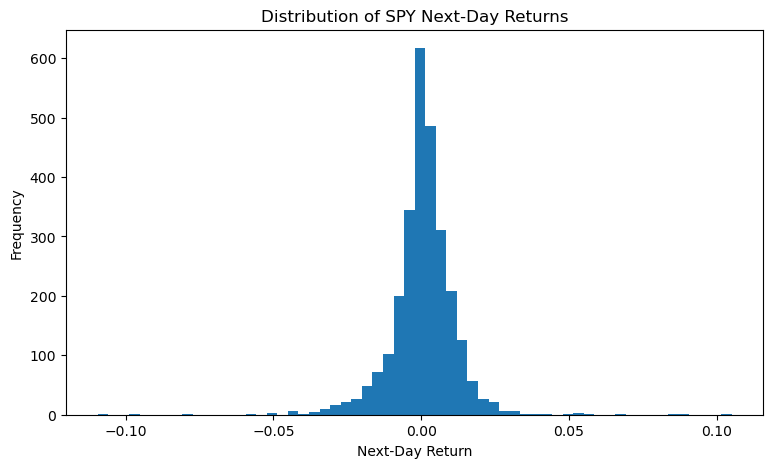

In [23]:
print(
    model_df["Next_Day_Return"].describe()
)

plt.figure(figsize=(9, 5))

plt.hist(
    model_df["Next_Day_Return"],
    bins=60
)

plt.title("Distribution of SPY Next-Day Returns")
plt.xlabel("Next-Day Return")
plt.ylabel("Frequency")

plt.show()

In [ ]:
## 12. Correlation Analysis

#The relationships among the selected predictors and the target are examined before regression.

#Very strong correlation among predictors can make individual regression coefficients difficult to interpret.

In [24]:
correlation_matrix = model_df[
    features + ["Next_Day_Return"]
].corr()

print(correlation_matrix.round(3))

                 Daily_Return  Return_5D  Return_20D  Relative_Range  \
Daily_Return            1.000      0.409       0.207          -0.143   
Return_5D               0.409      1.000       0.466          -0.431   
Return_20D              0.207      0.466       1.000          -0.531   
Relative_Range         -0.143     -0.431      -0.531           1.000   
Volume_Ratio           -0.270     -0.457      -0.241           0.502   
Volatility_20D          0.022     -0.025      -0.400           0.641   
Next_Day_Return        -0.122     -0.052      -0.038           0.021   

                 Volume_Ratio  Volatility_20D  Next_Day_Return  
Daily_Return           -0.270           0.022           -0.122  
Return_5D              -0.457          -0.025           -0.052  
Return_20D             -0.241          -0.400           -0.038  
Relative_Range          0.502           0.641            0.021  
Volume_Ratio            1.000          -0.058           -0.011  
Volatility_20D         -0.058    

In [25]:
correlation_matrix = model_df[
    features + ["Next_Day_Return"]
].corr()

print(correlation_matrix.round(3))

                 Daily_Return  Return_5D  Return_20D  Relative_Range  \
Daily_Return            1.000      0.409       0.207          -0.143   
Return_5D               0.409      1.000       0.466          -0.431   
Return_20D              0.207      0.466       1.000          -0.531   
Relative_Range         -0.143     -0.431      -0.531           1.000   
Volume_Ratio           -0.270     -0.457      -0.241           0.502   
Volatility_20D          0.022     -0.025      -0.400           0.641   
Next_Day_Return        -0.122     -0.052      -0.038           0.021   

                 Volume_Ratio  Volatility_20D  Next_Day_Return  
Daily_Return           -0.270           0.022           -0.122  
Return_5D              -0.457          -0.025           -0.052  
Return_20D             -0.241          -0.400           -0.038  
Relative_Range          0.502           0.641            0.021  
Volume_Ratio            1.000          -0.058           -0.011  
Volatility_20D         -0.058    

In [26]:
print(
    correlation_matrix["Next_Day_Return"]
    .sort_values(ascending=False)
)

Next_Day_Return    1.000000
Volatility_20D     0.033245
Relative_Range     0.021031
Volume_Ratio      -0.011456
Return_20D        -0.037714
Return_5D         -0.051713
Daily_Return      -0.121756
Name: Next_Day_Return, dtype: float64


In [ ]:
## 13. Chronological Train, Validation, and Test Split

Financial observations are ordered through time, so a random train-test split is not used.

The project uses:

- Training period: 2015–2022
- Validation period: 2023
- Final testing period: 2024–2025

Observations are assigned using Target_Date rather than the current feature date. This prevents a training observation from using a target that belongs to a later validation or test period.

In [27]:
train = model_df[
    model_df["Target_Date"] < "2023-01-01"
].copy()

validation = model_df[
    (model_df["Target_Date"] >= "2023-01-01") &
    (model_df["Target_Date"] < "2024-01-01")
].copy()

test = model_df[
    (model_df["Target_Date"] >= "2024-01-01") &
    (model_df["Target_Date"] <= "2025-12-31")
].copy()

print("Training observations:", len(train))
print("Validation observations:", len(validation))
print("Testing observations:", len(test))

Training observations: 1993
Validation observations: 250
Testing observations: 502


In [28]:
X_train = train[features]
y_train = train[target]

X_val = validation[features]
y_val = validation[target]

X_test = test[features]
y_test = test[target]

In [29]:
## 14. Baseline Model

Before evaluating Multiple Linear Regression, a simple baseline is created.

The baseline predicts the average next-day return from the training dataset for every future observation.

The regression model should provide better predictive performance than this simple benchmark to demonstrate useful predictive value.

SyntaxError: invalid syntax (2731295878.py, line 3)

In [30]:
baseline_value = y_train.mean()

print(
    "Training average next-day return:",
    baseline_value
)

baseline_val_pred = np.full(
    len(y_val),
    baseline_value
)

Training average next-day return: 0.00046325665321126134


In [31]:
baseline_val_mae = mean_absolute_error(
    y_val,
    baseline_val_pred
)

baseline_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        baseline_val_pred
    )
)

baseline_val_r2 = r2_score(
    y_val,
    baseline_val_pred
)

print("Baseline Validation MAE:", baseline_val_mae)
print("Baseline Validation RMSE:", baseline_val_rmse)
print("Baseline Validation R²:", baseline_val_r2)

Baseline Validation MAE: 0.006436588052043978
Baseline Validation RMSE: 0.008235732749860928
Baseline Validation R²: -0.00371378691809765


In [ ]:
## 15. Multiple Linear Regression

Multiple Linear Regression is used to estimate the relationship between current market conditions and SPY's next-day return.

The model estimates one coefficient for each selected predictor together with an intercept.

In [32]:
regression_model = LinearRegression()

regression_model.fit(
    X_train,
    y_train
)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [34]:
val_predictions = regression_model.predict(
    X_val
)

In [ ]:
## 16. Validation Performance

The regression model is evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)

MAE measures the average absolute prediction error.

RMSE places greater penalty on large errors.

R² measures the proportion of variation in next-day returns explained by the regression model.

In [35]:
val_mae = mean_absolute_error(
    y_val,
    val_predictions
)

val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        val_predictions
    )
)

val_r2 = r2_score(
    y_val,
    val_predictions
)

print("Regression Validation MAE:", val_mae)
print("Regression Validation RMSE:", val_rmse)
print("Regression Validation R²:", val_r2)

Regression Validation MAE: 0.006671732946999723
Regression Validation RMSE: 0.008410508370741105
Regression Validation R²: -0.046766689231295455


In [36]:
validation_results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Multiple Linear Regression"
    ],
    "MAE": [
        baseline_val_mae,
        val_mae
    ],
    "RMSE": [
        baseline_val_rmse,
        val_rmse
    ],
    "R2": [
        baseline_val_r2,
        val_r2
    ]
})

validation_results

,Model,MAE,RMSE,R2
0,Baseline,0.006437,0.008236,-0.003714
1,Multiple Linear Regression,0.006672,0.008411,-0.046767


In [37]:
## 17. Final Model Training

After the regression specification is finalized using the training and validation periods, the final model is fitted using all observations from 2015 through 2023.

The untouched 2024–2025 observations are then used only once for final evaluation.

SyntaxError: invalid character '–' (U+2013) (2442533864.py, line 5)

In [38]:
train_validation = pd.concat(
    [train, validation],
    ignore_index=True
)

X_train_final = train_validation[features]
y_train_final = train_validation[target]

final_model = LinearRegression()

final_model.fit(
    X_train_final,
    y_train_final
)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [39]:
test_predictions = final_model.predict(
    X_test
)

In [40]:
final_baseline_value = y_train_final.mean()

baseline_test_predictions = np.full(
    len(y_test),
    final_baseline_value
)

In [41]:
test_mae = mean_absolute_error(
    y_test,
    test_predictions
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        test_predictions
    )
)

test_r2 = r2_score(
    y_test,
    test_predictions
)

baseline_test_mae = mean_absolute_error(
    y_test,
    baseline_test_predictions
)

baseline_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_test_predictions
    )
)

baseline_test_r2 = r2_score(
    y_test,
    baseline_test_predictions
)

print("FINAL REGRESSION RESULTS")
print("------------------------")
print("MAE:", test_mae)
print("RMSE:", test_rmse)
print("R²:", test_r2)

print("\nBASELINE RESULTS")
print("----------------")
print("MAE:", baseline_test_mae)
print("RMSE:", baseline_test_rmse)
print("R²:", baseline_test_r2)

FINAL REGRESSION RESULTS
------------------------
MAE: 0.006638132572870261
RMSE: 0.010259246705893777
R²: 0.007440443967360655

BASELINE RESULTS
----------------
MAE: 0.0065995038342926615
RMSE: 0.010301548933442196
R²: -0.00076172631927518


In [42]:
final_results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Multiple Linear Regression"
    ],
    "MAE": [
        baseline_test_mae,
        test_mae
    ],
    "RMSE": [
        baseline_test_rmse,
        test_rmse
    ],
    "R2": [
        baseline_test_r2,
        test_r2
    ]
})

final_results

,Model,MAE,RMSE,R2
0,Baseline,0.006600,0.010302,-0.000762
1,Multiple Linear Regression,0.006638,0.010259,0.007440


In [43]:
final_results_percent = final_results.copy()

final_results_percent["MAE (%)"] = (
    final_results_percent["MAE"] * 100
)

final_results_percent["RMSE (%)"] = (
    final_results_percent["RMSE"] * 100
)

final_results_percent[
    [
        "Model",
        "MAE (%)",
        "RMSE (%)",
        "R2"
    ]
]

,Model,MAE (%),RMSE (%),R2
0,Baseline,0.659950,1.030155,-0.000762
1,Multiple Linear Regression,0.663813,1.025925,0.007440


In [ ]:
## 18. Actual Versus Predicted Returns

Actual next-day returns are compared with the predictions produced by the final regression model.

If the regression model has strong predictive ability, predicted and actual values should display a clear positive relationship.

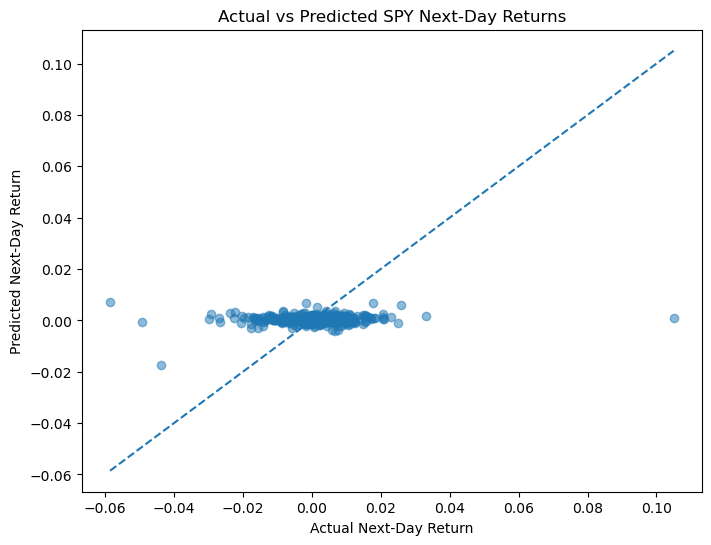

In [44]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.5
)

minimum = min(
    y_test.min(),
    test_predictions.min()
)

maximum = max(
    y_test.max(),
    test_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title(
    "Actual vs Predicted SPY Next-Day Returns"
)

plt.xlabel(
    "Actual Next-Day Return"
)

plt.ylabel(
    "Predicted Next-Day Return"
)

plt.show()

In [ ]:
## 19. Regression Coefficients

The fitted coefficients indicate the estimated direction of the relationship between each predictor and next-day return while the other predictors are held constant.

Coefficient signs are interpreted as associations rather than evidence of causation.

In [45]:
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": final_model.coef_
})

coefficients = coefficients.sort_values(
    "Coefficient",
    ascending=False
)

coefficients

,Feature,Coefficient
5,Volatility_20D,0.085147
4,Volume_Ratio,-0.001171
2,Return_20D,-0.002102
1,Return_5D,-0.003677
3,Relative_Range,-0.041610
0,Daily_Return,-0.138059


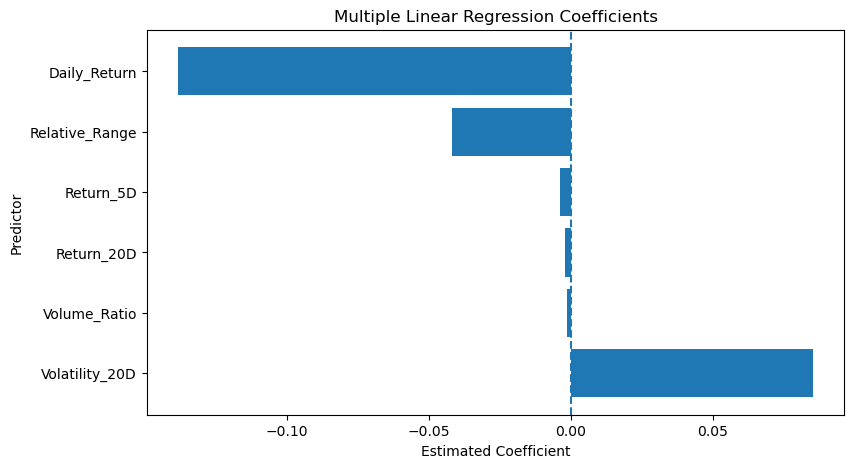

In [46]:
plt.figure(figsize=(9, 5))

plt.barh(
    coefficients["Feature"],
    coefficients["Coefficient"]
)

plt.title(
    "Multiple Linear Regression Coefficients"
)

plt.xlabel(
    "Estimated Coefficient"
)

plt.ylabel(
    "Predictor"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.show()

In [ ]:
## 20. Residual Analysis

Residuals represent the difference between actual and predicted returns.

The residual distribution is examined to identify whether the regression model systematically underpredicts or overpredicts returns and whether large unexplained movements remain.

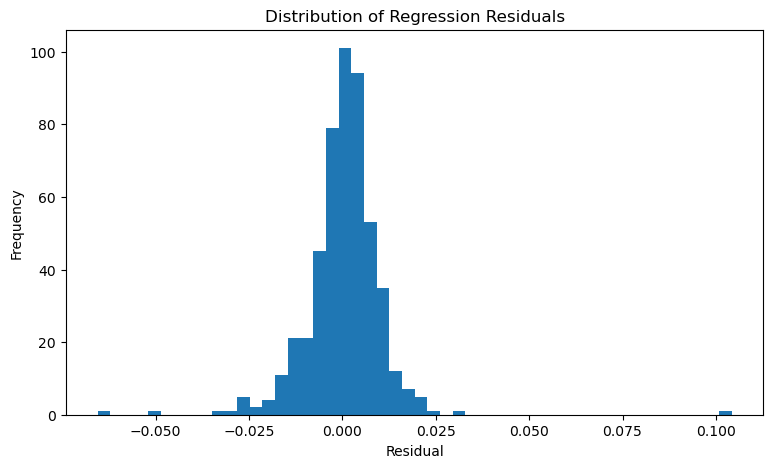

In [47]:
residuals = (
    y_test.values - test_predictions
)

plt.figure(figsize=(9, 5))

plt.hist(
    residuals,
    bins=50
)

plt.title(
    "Distribution of Regression Residuals"
)

plt.xlabel(
    "Residual"
)

plt.ylabel(
    "Frequency"
)

plt.show()

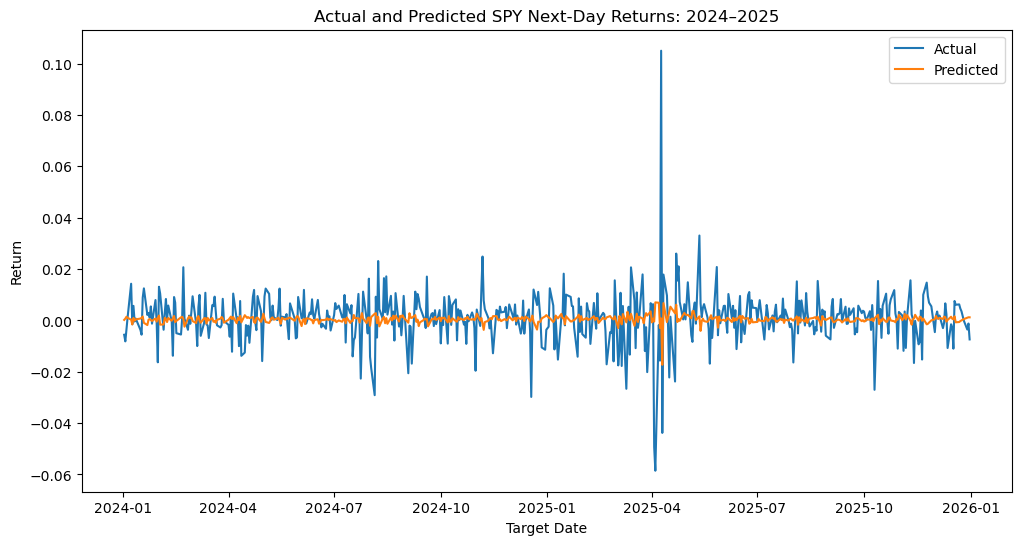

In [48]:
prediction_results = test[
    [
        "Date",
        "Target_Date",
        "Next_Day_Return"
    ]
].copy()

prediction_results[
    "Predicted_Next_Day_Return"
] = test_predictions

plt.figure(figsize=(12, 6))

plt.plot(
    prediction_results["Target_Date"],
    prediction_results["Next_Day_Return"],
    label="Actual"
)

plt.plot(
    prediction_results["Target_Date"],
    prediction_results[
        "Predicted_Next_Day_Return"
    ],
    label="Predicted"
)

plt.title(
    "Actual and Predicted SPY Next-Day Returns: 2024–2025"
)

plt.xlabel("Target Date")
plt.ylabel("Return")

plt.legend()

plt.show()

In [49]:
prediction_results.to_csv(
    "regression_test_predictions.csv",
    index=False
)

final_results.to_csv(
    "regression_model_metrics.csv",
    index=False
)

coefficients.to_csv(
    "regression_coefficients.csv",
    index=False
)

print("Regression output files saved.")

Regression output files saved.


In [ ]:
## 21. Interpretation

The Multiple Linear Regression model was used to predict SPY's next-day percentage return using recent returns, market momentum, intraday price range, relative trading volume, and rolling volatility.

The final model was evaluated on an untouched 2024–2025 test period.

The regression model produced only a very small R-squared value, indicating that the selected historical market indicators explained very little of the variation in next-day SPY returns.

The regression model produced a slightly lower RMSE than the simple baseline, but its MAE was not better than the baseline. Therefore, the evidence does not support the conclusion that this Multiple Linear Regression model provides strong next-day forecasting ability.

The results suggest that next-day SPY returns are difficult to predict using only simple historical price, volume, momentum, and volatility indicators.

This is still an important analytical result because weak predictive performance demonstrates the limits of simple historical-data-based forecasting rather than evidence that the analysis failed.

In [ ]:
## 22. Limitations

This analysis has several limitations.

First, only historical SPY price and volume information is used. The model does not include macroeconomic announcements, interest rates, earnings information, news sentiment, geopolitical events, or other external factors that may influence the market.

Second, Multiple Linear Regression assumes a linear relationship between predictors and the target. Stock-market behaviour may involve nonlinear relationships and interactions that a linear model cannot capture.

Third, daily financial returns contain substantial random variation, making short-term forecasting particularly difficult.

Finally, model performance during the 2015–2025 period does not guarantee similar behaviour in future market conditions.

The analysis is conducted for academic purposes and should not be interpreted as investment advice.

In [ ]:
## 23. Conclusion

The regression analysis investigated whether historical SPY market indicators could predict the magnitude of the next trading day's return.

Although some historical variables showed relationships with future returns, the final Multiple Linear Regression model demonstrated very limited predictive power on the 2024–2025 test period.

The findings indicate that predicting exact next-day SPY returns using a simple linear combination of historical price, volume, momentum, and volatility indicators is difficult.

These results complement the team's other analytics approaches. Classification examines whether the market moves up or down, clustering identifies similar market conditions, and association-rule analysis investigates combinations of conditions that occur with future movements.